# Steps 3 + 4: Diffusion smoothing and MMR selection (your first complete extractive system)

Reads the sentence probabilities from Step 2 and turns them into extractive summaries in three stages, each tuned **on the validation set only** and each switched on **only if it helps**:

1. **Diffusion** (Step 3): spread scores over the document graph. Tunes alpha, K, which edge types carry it.
2. **MMR** (Step 4): pick sentences that are high-scoring *and* non-redundant (InLegalBERT cosine). Tunes lambda and candidate-pool size.
3. **Length**: the word budget is the mean reference length from your training set, times a factor tuned on validation.

It also adds a **3-seed ensemble** of the full GNN, Lead / TextRank / Oracle baselines, paired-bootstrap tests, and exports (a) the final extractive summaries and (b) a longer sentence selection to feed LED in Step 5.

**Runtime: CPU is enough.** Edit the paths in cell 2. This notebook replaces the separate Step 3 notebook.

In [1]:
!pip -q install rouge-score scipy tqdm pandas
from google.colab import drive
drive.mount('/content/drive')

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Mounted at /content/drive


In [2]:
import os, re, json, math, time, warnings
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, torch
from scipy.sparse import coo_matrix, identity, diags
from tqdm.auto import tqdm
warnings.filterwarnings("ignore")

# ============ EDIT THESE (same BASE as Steps 0-2) ============
BASE        = "/content/drive/MyDrive/inabs_project"
GRAPH_DIR   = f"{BASE}/graphs"       # Step 1
GNN_DIR     = f"{BASE}/gnn"          # Step 2
OUT_DIR     = f"{BASE}/extractive"   # this notebook
SPLIT_NAMES = ["train", "validate", "test"]
# =============================================================

POSTPROC_EXPERIMENTS = ["mlp_feat", "gnn_full"]   # which Step 2 models get diffusion + MMR (add others for a fuller table; slower)
USE_ENSEMBLE = True          # also build "gnn_full_ens": mean of the full-GNN probabilities over all seeds

# stage 1: diffusion grid
ALPHAS = [0.2, 0.4, 0.6, 0.8]
KS     = [2, 5, 10]
GRAPHS = {"all": [0, 1, 2], "ent_sem": [0, 1], "sem_seq": [1, 2]}    # Step 1 relations: 0 entity, 1 semantic, 2 sequential
NORMS  = ["sym"]             # "sym" = D^-1/2 A D^-1/2 ; "rw" = D^-1 A.  ["sym", "rw"] tries both
# stage 2: MMR grid
LAMBDAS     = [0.9, 0.8, 0.7, 0.6, 0.5]   # 1.0 (= plain top-k) is always the baseline
N_CANDS     = [30, 50, 80]
RED_SOURCES = ["centered"]   # redundancy similarity: "centered" = mean-centred InLegalBERT cosine (recommended), "raw" = plain cosine
POOL_FACTOR = 1.5            # candidate pool is extended until it holds >= 1.5x the word budget, so MMR always has a choice
# stage 3: length
SCALES = [0.8, 0.9, 1.0, 1.1, 1.2, 1.3]

MIN_GAIN = 5e-4              # a stage must beat the previous stage on validation by this much (0.05 ROUGE points) to be used
LED_MAX_WORDS = 2500         # cap for the longer selection exported for LED
COMPUTE_ROUGE_L = True       # official ROUGE-L on test (~0.5 s per document per evaluation)
N_BOOT = 10000

for d in ("summaries/extractive", "summaries/led_input", "figures"): Path(OUT_DIR, d).mkdir(parents=True, exist_ok=True)

## 1. Load graphs, Step 2 predictions and budgets

In [3]:
GR, by_split, DOC2IDX = [], {s: [] for s in SPLIT_NAMES}, {}
for split in SPLIT_NAMES:
    for p in sorted(Path(GRAPH_DIR, split).glob("*.pt")):
        g = torch.load(p, map_location="cpu", weights_only=True)
        DOC2IDX[(split, g["doc_id"])] = len(GR); by_split[split].append(len(GR)); GR.append(g)
print({s: len(v) for s, v in by_split.items()}, "graphs")
assert all(len(v) > 0 for v in by_split.values()), "a split has no graphs - check GRAPH_DIR"
EMB_DIM = GR[0]["emb_dim"]
val_idx, test_idx = by_split["validate"], by_split["test"]

pre = torch.load(Path(GNN_DIR, "preproc.pt"), weights_only=True)
BUDGET = int(pre["budget"])                                     # mean reference length (words), train set
WORDS = {i: g["sent_words"].tolist() for i, g in enumerate(GR)}
ORACLE_WORDS = float(np.mean([sum(WORDS[i][j] for j in GR[i]["oracle_idx"]) for i in by_split["train"]]))
LED_BUDGET = int(min(ORACLE_WORDS, LED_MAX_WORDS))              # LED is trained on oracle-length inputs, so match that
print(f"extractive budget: {BUDGET} words | LED-input budget: {LED_BUDGET} words (mean oracle length {ORACLE_WORDS:.0f})")

RUNS = {}
for p in sorted(Path(GNN_DIR, "runs").glob("*.json")):
    r = json.load(open(p)); RUNS[(r["name"], r["seed"])] = r
assert RUNS, "no Step 2 runs found in " + str(Path(GNN_DIR, "runs"))
assert all(r["budget"] == BUDGET for r in RUNS.values()), "budget differs between Step 2 runs"

SEEDS = {}
for (n, s) in RUNS: SEEDS.setdefault(n, []).append(s)
SEEDS = {n: sorted(v) for n, v in SEEDS.items()}

SCORES = {}                                                     # (experiment, seed) -> {graph index: float32 probabilities}
for (name, seed) in RUNS:
    d = torch.load(Path(GNN_DIR, "preds", f"{name}_seed{seed}.pt"), weights_only=True)
    out = {}
    for split in SPLIT_NAMES:
        for doc_id, t in d[split].items():
            i = DOC2IDX[(split, doc_id)]
            assert len(t) == GR[i]["num_nodes"], f"{doc_id}: {len(t)} scores vs {GR[i]['num_nodes']} sentences"
            out[i] = t.numpy().astype(np.float32)
    assert len(out) == len(GR), f"{name} seed {seed}: predictions missing for some documents"
    SCORES[(name, seed)] = out

if USE_ENSEMBLE and len(SEEDS.get("gnn_full", [])) >= 2:
    SCORES[("gnn_full_ens", 0)] = {i: np.mean([SCORES[("gnn_full", s)][i] for s in SEEDS["gnn_full"]], axis=0).astype(np.float32) for i in range(len(GR))}
    SEEDS["gnn_full_ens"] = [0]
EXPS = [e for e in POSTPROC_EXPERIMENTS + (["gnn_full_ens"] if "gnn_full_ens" in SEEDS else []) if e in SEEDS]
LABELS = {"mlp_emb": "MLP, embeddings only", "mlp_feat": "MLP, embeddings + node features", "gnn_entity": "GNN, entity edges",
          "gnn_ent_sem": "GNN, entity + semantic", "gnn_full": "GNN, full graph", "gnn_full_ens": "GNN, full graph, seed ensemble"}
print("post-processing:", {e: SEEDS[e] for e in EXPS})

{'train': 300, 'validate': 60, 'test': 100} graphs
extractive budget: 898 words | LED-input budget: 1237 words (mean oracle length 1237)
post-processing: {'mlp_feat': [0, 1, 2], 'gnn_full': [0, 1, 2], 'gnn_full_ens': [0]}


## 2. Machinery: fast ROUGE, diffusion, MMR, baselines

In [4]:
from rouge_score import rouge_scorer, tokenizers
TOK = tokenizers.DefaultTokenizer(use_stemmer=True)
class _CachedStemmer:
    def __init__(self, st): self.st, self.c = st, {}
    def stem(self, w):
        r = self.c.get(w)
        if r is None: r = self.c[w] = self.st.stem(w)
        return r
if getattr(TOK, "_stemmer", None) is not None: TOK._stemmer = _CachedStemmer(TOK._stemmer)

def ngr(t, n): return Counter(zip(*[t[i:] for i in range(n)])) if len(t) >= n else Counter()
def f1(ov, ct, rt):
    if ov <= 0 or ct <= 0 or rt <= 0: return 0.0
    p, r = ov / ct, ov / rt
    return 2 * p * r / (p + r)

CACHE = {}
for idx, g in enumerate(tqdm(GR, desc="caching n-grams")):
    rt = TOK.tokenize(g["reference"]); r1, r2 = ngr(rt, 1), ngr(rt, 2)
    c1, c2, L1, L2 = [], [], [], []
    for s in g["sentences"]:
        t = TOK.tokenize(s); a, b = ngr(t, 1), ngr(t, 2)
        c1.append(Counter({k: v for k, v in a.items() if k in r1})); c2.append(Counter({k: v for k, v in b.items() if k in r2}))
        L1.append(len(t)); L2.append(max(len(t) - 1, 0))
    CACHE[idx] = dict(r1=r1, r2=r2, R1=len(rt), R2=max(len(rt) - 1, 0), c1=c1, c2=c2, L1=L1, L2=L2)

def fast_eval(idxs, selector):
    """per-document fast ROUGE-1/2 F, recall and summary length"""
    F, R, W = [], [], []
    for i in idxs:
        sel = selector(i); d = CACHE[i]; s1, s2, t1, t2 = Counter(), Counter(), 0, 0
        for j in sel: s1.update(d["c1"][j]); s2.update(d["c2"][j]); t1 += d["L1"][j]; t2 += d["L2"][j]
        ov1 = sum(min(c, d["r1"][k]) for k, c in s1.items()); ov2 = sum(min(c, d["r2"][k]) for k, c in s2.items())
        F.append((f1(ov1, t1, d["R1"]), f1(ov2, t2, d["R2"]))); R.append((ov1 / max(d["R1"], 1), ov2 / max(d["R2"], 1)))
        W.append(sum(WORDS[i][j] for j in sel))
    F, R = np.array(F), np.array(R)
    return dict(score=(F[:, 0] + F[:, 1]) / 2, r1=F[:, 0], r2=F[:, 1], rec1=R[:, 0], rec2=R[:, 1], words=np.array(W))

def official_eval(idxs, selector):
    sc = rouge_scorer.RougeScorer(["rouge1", "rouge2"] + (["rougeL"] if COMPUTE_ROUGE_L else []), use_stemmer=True)
    acc = {"rouge1": [], "rouge2": [], "rougeL": []}
    for i in idxs:
        sel = selector(i)
        s = sc.score(GR[i]["reference"], " ".join(GR[i]["sentences"][j] for j in sel))
        for k in s: acc[k].append(s[k].fmeasure)
    return {k: float(np.mean(v)) for k, v in acc.items() if v}

# ---------------- diffusion ----------------
def build_P(g, rels, norm):
    n = g["num_nodes"]
    ei, et, ew = g["edge_index"].numpy(), g["edge_type"].numpy(), g["edge_weight"].numpy()
    m = np.isin(et, rels)
    A = coo_matrix((ew[m], (ei[0][m], ei[1][m])), shape=(n, n)).tocsr()          # duplicates from different relations are summed
    A = (A + A.T) * 0.5 + identity(n, format="csr")                               # symmetrise + self-loops
    d = np.asarray(A.sum(1)).ravel()
    P = diags(1.0 / np.sqrt(d)) @ A @ diags(1.0 / np.sqrt(d)) if norm == "sym" else diags(1.0 / d) @ A
    return P.tocsr().astype(np.float32)

_P = {}
def get_P(i, gname, norm):
    k = (i, gname, norm)
    if k not in _P: _P[k] = build_P(GR[i], GRAPHS[gname], norm)
    return _P[k]

def diffuse(P, s0, alpha, K):
    if alpha <= 0: return s0
    s = s0
    for _ in range(K): s = (1.0 - alpha) * s0 + alpha * (P @ s)
    return s

# ---------------- MMR ----------------
_S = {}
def get_S(i, kind):
    """redundancy matrix: cosine of InLegalBERT sentence embeddings (mean-centred per document), clipped at 0"""
    k = (i, kind)
    if k not in _S:
        E = GR[i]["x"][:, :EMB_DIM].numpy().astype(np.float32)
        if kind == "centered": E = E - E.mean(0, keepdims=True)
        E = E / np.maximum(np.linalg.norm(E, axis=1, keepdims=True), 1e-8)
        S = E @ E.T; np.fill_diagonal(S, 0.0)
        _S[k] = np.clip(S, 0.0, None).astype(np.float32)
    return _S[k]

def minmax(s):
    lo, hi = float(np.min(s)), float(np.max(s))
    return (s - lo) / (hi - lo) if hi > lo else np.zeros_like(s)

def select_topk(scores, words, budget):
    chosen, w = [], 0
    for i in np.argsort(-np.asarray(scores), kind="stable"):
        chosen.append(int(i)); w += words[i]
        if w >= budget: break
    return sorted(chosen)

def mmr_select(score, S, words, budget, lam, n_cand, pool_factor):
    """score: min-max normalised (n,). Candidate pool = top n_cand, extended until it holds pool_factor x budget words."""
    order = np.argsort(-score, kind="stable"); cand, w = [], 0
    for k, i in enumerate(order):
        if k >= n_cand and w >= pool_factor * budget: break
        cand.append(int(i)); w += words[i]
    cand = np.array(cand); sc = score[cand]; Sc = S[np.ix_(cand, cand)]
    max_sim, taken, chosen, total = np.zeros(len(cand)), np.zeros(len(cand), bool), [], 0
    while total < budget and not taken.all():
        m = lam * sc - (1.0 - lam) * max_sim; m[taken] = -np.inf
        j = int(np.argmax(m)); taken[j] = True; chosen.append(int(cand[j])); total += words[cand[j]]
        max_sim = np.maximum(max_sim, Sc[j])
    return sorted(chosen)

# ---------------- one config -> one selector ----------------
_DS = {}
def ranked_scores(exp, seed, dk, i):
    key = (exp, seed, dk)
    memo = _DS.setdefault(key, {})
    if i not in memo:
        s = SCORES[(exp, seed)][i]
        memo[i] = s if dk is None else diffuse(get_P(i, dk[0], dk[1]), s, dk[2], dk[3])
    return memo[i]

def make_selector(exp, seed, cfg, budget=None):
    b = budget if budget is not None else BUDGET * cfg["scale"]
    dk = None if cfg["diff"] is None else (cfg["diff"]["graph"], cfg["diff"]["norm"], cfg["diff"]["alpha"], cfg["diff"]["K"])
    def sel(i):
        s = ranked_scores(exp, seed, dk, i)
        if cfg["mmr"] is None: return select_topk(s, WORDS[i], b)
        m = cfg["mmr"]
        return mmr_select(minmax(s), get_S(i, m["red"]), WORDS[i], b, m["lam"], m["n_cand"], POOL_FACTOR)
    return sel

# ---------------- baselines (no model) ----------------
def textrank_scores(i, damping=0.85, iters=50):
    S = get_S(i, "centered"); rs = S.sum(1, keepdims=True); rs[rs == 0] = 1.0
    Pm = S / rs; n = len(S); r = np.full(n, 1.0 / n, dtype=np.float32)
    for _ in range(iters): r = (1 - damping) / n + damping * (Pm.T @ r)
    return r
BASELINES = {
    "Lead (first sentences)":            lambda i: select_topk(np.arange(len(WORDS[i]))[::-1], WORDS[i], BUDGET),
    "TextRank (InLegalBERT similarity)": lambda i: select_topk(textrank_scores(i), WORDS[i], BUDGET),
    "Oracle (upper bound)":              lambda i: sorted(GR[i]["oracle_idx"]),
}

caching n-grams:   0%|          | 0/460 [00:00<?, ?it/s]

In [5]:
# ---- unit checks (fail loudly here rather than silently later)
exp0 = EXPS[0]; sd0 = SEEDS[exp0][0]; i0 = test_idx[0]; g0 = GR[i0]; s0 = SCORES[(exp0, sd0)][i0]
P0 = get_P(i0, "all", NORMS[0])
if NORMS[0] == "sym":
    closed = 0.5 * np.linalg.solve(np.eye(g0["num_nodes"]) - 0.5 * P0.toarray(), s0)
    assert np.allclose(diffuse(P0, s0, 0.5, 80), closed, atol=1e-4), "diffusion does not converge to the closed form"
assert np.array_equal(diffuse(P0, s0, 0.0, 10), s0)
for i in by_split["validate"][:20]:                         # MMR with lambda = 1 must reproduce plain top-k
    s = SCORES[(exp0, sd0)][i]
    assert mmr_select(minmax(s), get_S(i, "centered"), WORDS[i], BUDGET, 1.0, 30, POOL_FACTOR) == select_topk(s, WORDS[i], BUDGET)
for i in by_split["validate"][:20]:                         # MMR output: unique, sorted, reaches the budget (or the whole document)
    sel = mmr_select(minmax(SCORES[(exp0, sd0)][i]), get_S(i, "centered"), WORDS[i], BUDGET, 0.7, 30, POOL_FACTOR)
    assert sel == sorted(set(sel)) and (sum(WORDS[i][j] for j in sel) >= BUDGET or len(sel) == len(WORDS[i]))
print("unit checks passed (diffusion closed form, MMR(lambda=1) == top-k, MMR output valid)")

unit checks passed (diffusion closed form, MMR(lambda=1) == top-k, MMR output valid)


## 3. Tune the three stages on the VALIDATION set (per experiment, averaged over its seeds)

In [6]:
def val_of(exp, cfg):
    return float(np.mean([fast_eval(val_idx, make_selector(exp, sd, cfg))["score"].mean() for sd in SEEDS[exp]]))

STAGES, TUNING = {}, {}
t0 = time.time()
for exp in EXPS:
    cfg = dict(diff=None, mmr=None, scale=1.0)
    v_prev = v0 = val_of(exp, cfg); stages = [("top-k (no post-processing)", json.loads(json.dumps(cfg)), v0)]
    tune = {}

    # ---- stage 1: diffusion
    rows = []
    for gn in GRAPHS:
        for nm in NORMS:
            for a in ALPHAS:
                for K in KS:
                    c = dict(diff=dict(graph=gn, norm=nm, alpha=a, K=K), mmr=None, scale=1.0)
                    rows.append(dict(graph=gn, norm=nm, alpha=a, K=K, val=val_of(exp, c)))
    tune["s1"] = pd.DataFrame(rows); b = max(rows, key=lambda r: r["val"])
    if b["val"] - v_prev >= MIN_GAIN:
        cfg["diff"] = dict(graph=b["graph"], norm=b["norm"], alpha=b["alpha"], K=b["K"]); v_prev = b["val"]
        stages.append(("+ diffusion", json.loads(json.dumps(cfg)), v_prev))

    # ---- stage 2: MMR
    rows = []
    for red in RED_SOURCES:
        for lam in LAMBDAS:
            for nc in N_CANDS:
                c = dict(diff=cfg["diff"], mmr=dict(lam=lam, n_cand=nc, red=red), scale=1.0)
                rows.append(dict(red=red, lam=lam, n_cand=nc, val=val_of(exp, c)))
    tune["s2"] = pd.DataFrame(rows); b = max(rows, key=lambda r: r["val"])
    if b["val"] - v_prev >= MIN_GAIN:
        cfg["mmr"] = dict(lam=b["lam"], n_cand=b["n_cand"], red=b["red"]); v_prev = b["val"]
        stages.append(("+ MMR", json.loads(json.dumps(cfg)), v_prev))

    # ---- stage 3: length factor
    rows = [dict(scale=sc, val=val_of(exp, dict(diff=cfg["diff"], mmr=cfg["mmr"], scale=sc))) for sc in SCALES]
    tune["s3"] = pd.DataFrame(rows); b = max(rows, key=lambda r: r["val"])
    if b["scale"] != 1.0 and b["val"] - v_prev >= MIN_GAIN:
        cfg["scale"] = b["scale"]; v_prev = b["val"]
        stages.append(("+ length factor", json.loads(json.dumps(cfg)), v_prev))

    STAGES[exp], TUNING[exp] = stages, tune
    print(f"\n{exp}: validation (R1+R2)/2   " + "  ->  ".join(f"{n.replace('+ ', '')} {v:.4f}" for n, _, v in stages))
    fc = stages[-1][1]
    print("   final:", "diffusion " + str(fc["diff"]) if fc["diff"] else "no diffusion", "|", "MMR " + str(fc["mmr"]) if fc["mmr"] else "no MMR", "| length x", fc["scale"])
print(f"\ntuning finished in {(time.time() - t0) / 60:.1f} min")


mlp_feat: validation (R1+R2)/2   top-k (no post-processing) 0.4422  ->  MMR 0.4427  ->  length factor 0.4444
   final: no diffusion | MMR {'lam': 0.7, 'n_cand': 50, 'red': 'centered'} | length x 0.9

gnn_full: validation (R1+R2)/2   top-k (no post-processing) 0.4440  ->  length factor 0.4453
   final: no diffusion | no MMR | length x 0.8

gnn_full_ens: validation (R1+R2)/2   top-k (no post-processing) 0.4398  ->  diffusion 0.4420  ->  MMR 0.4457  ->  length factor 0.4468
   final: diffusion {'graph': 'sem_seq', 'norm': 'sym', 'alpha': 0.2, 'K': 5} | MMR {'lam': 0.6, 'n_cand': 80, 'red': 'centered'} | length x 0.8

tuning finished in 0.3 min


## 4. Test results: every active stage vs the previous one (official ROUGE), baselines, paired bootstrap

In [7]:
OFF, DOCS = {}, {}
def stage_official(exp, sd, k, cfg):
    key = (exp, sd, k)
    if key not in OFF:
        if k == 0 and (exp, sd) in RUNS:                                       # identical selection rule as Step 2 -> reuse its numbers
            t = RUNS[(exp, sd)]["test"]; OFF[key] = {m: t[m] for m in ("rouge1", "rouge2", "rougeL") if m in t}
        else:
            OFF[key] = official_eval(test_idx, make_selector(exp, sd, cfg))
    return OFF[key]

def ms(v):
    v = np.array(v) * 100
    return f"{v.mean():.2f} ± {v.std():.2f}" if len(v) > 1 else f"{v.mean():.2f}"

rows, boot, rng = [], [], np.random.default_rng(0)
for exp in EXPS:
    for k, (name, cfg, _) in enumerate(STAGES[exp]):
        offs, vals, docs = [], [], []
        for sd in SEEDS[exp]:
            sel = make_selector(exp, sd, cfg)
            ev = fast_eval(test_idx, sel); docs.append(ev["score"])
            vals.append(fast_eval(val_idx, sel)["score"].mean())
            offs.append(stage_official(exp, sd, k, cfg))
            if k == 0 and (exp, sd) in RUNS and abs(ev["score"].mean() - RUNS[(exp, sd)]["test"]["score"]) > 1e-5:
                print(f"  note: {exp} seed {sd}: recomputed top-k test score differs from Step 2 ({ev['score'].mean():.5f} vs {RUNS[(exp, sd)]['test']['score']:.5f})")
        DOCS[(exp, k)] = np.mean(docs, 0)
        r = {"Model": LABELS[exp] + ("" if k == 0 else " " + name), "Val score": ms(vals),
             "Test R-1": ms([o["rouge1"] for o in offs]), "Test R-2": ms([o["rouge2"] for o in offs])}
        if COMPUTE_ROUGE_L and all("rougeL" in o for o in offs): r["Test R-L"] = ms([o["rougeL"] for o in offs])
        r["Words"] = f"{ev['words'].mean():.0f}"
        rows.append(r)
        if k > 0:
            d = DOCS[(exp, k)] - DOCS[(exp, k - 1)]
            bs = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(N_BOOT)])
            boot.append({"Model": LABELS[exp], "Stage": name.replace("+ ", "added: "), "gain (R1+R2)/2 x100": round(d.mean() * 100, 2),
                         "95% CI": f"[{np.percentile(bs, 2.5) * 100:.2f}, {np.percentile(bs, 97.5) * 100:.2f}]",
                         "P(gain<=0)": round(float((bs <= 0).mean()), 3), "docs improved": f"{int((d > 0).sum())}/{len(d)}"})
for name, sel in BASELINES.items():
    o = official_eval(test_idx, sel); ev = fast_eval(test_idx, sel)
    r = {"Model": name, "Val score": "-", "Test R-1": f"{o['rouge1'] * 100:.2f}", "Test R-2": f"{o['rouge2'] * 100:.2f}"}
    if COMPUTE_ROUGE_L: r["Test R-L"] = f"{o['rougeL'] * 100:.2f}"
    r["Words"] = f"{ev['words'].mean():.0f}"; rows.append(r)

TABLE = pd.DataFrame(rows); TABLE.to_csv(Path(OUT_DIR, "results_table.csv"), index=False)
print(TABLE.to_string(index=False))
print("\nVal score = validation (ROUGE-1 + ROUGE-2)/2 of that stage. Words = mean summary length on test.")
if boot:
    BOOT = pd.DataFrame(boot); BOOT.to_csv(Path(OUT_DIR, "bootstrap.csv"), index=False)
    print("\nPaired bootstrap on the test documents (each active stage vs the stage before it):"); print(BOOT.to_string(index=False))

                                          Model    Val score     Test R-1     Test R-2     Test R-L Words
                MLP, embeddings + node features 44.22 ± 0.20 56.24 ± 0.56 35.88 ± 0.56 32.48 ± 0.64  1093
          MLP, embeddings + node features + MMR 44.27 ± 0.25 56.26 ± 0.37 35.84 ± 0.38 32.43 ± 0.46  1065
MLP, embeddings + node features + length factor 44.44 ± 0.30 56.80 ± 0.45 35.69 ± 0.42 32.49 ± 0.46  1010
                                GNN, full graph 44.40 ± 0.13 56.22 ± 0.34 35.96 ± 0.05 32.43 ± 0.09  1091
                GNN, full graph + length factor 44.53 ± 0.30 57.45 ± 0.28 35.69 ± 0.15 32.51 ± 0.28   967
                 GNN, full graph, seed ensemble        43.98        56.36        36.07        32.64  1114
     GNN, full graph, seed ensemble + diffusion        44.20        56.31        36.16        32.79  1131
           GNN, full graph, seed ensemble + MMR        44.57        56.54        36.13        32.69  1069
 GNN, full graph, seed ensemble + length facto

## 5. Export the final system
The final system is whichever full-GNN variant (best single seed or the seed ensemble) has the higher validation score. It is exported twice: the **extractive summary** (this is your fallback result) and a **longer selection for LED** (Step 5).

In [8]:
cands = [e for e in ("gnn_full", "gnn_full_ens") if e in EXPS]
FINAL_EXP = max(cands, key=lambda e: STAGES[e][-1][2]); FINAL_CFG = STAGES[FINAL_EXP][-1][1]
if FINAL_EXP == "gnn_full":
    bp = Path(GNN_DIR, "best_run.json")
    FINAL_SEED = json.load(open(bp))["seed"] if bp.exists() else max(SEEDS["gnn_full"], key=lambda s: RUNS[("gnn_full", s)]["val"]["score"])
else:
    FINAL_SEED = 0
print(f"final system: {FINAL_EXP} (seed {FINAL_SEED}) | validation {STAGES[FINAL_EXP][-1][2]:.4f}")

ext_sel = make_selector(FINAL_EXP, FINAL_SEED, FINAL_CFG)                     # extractive summary
led_sel = make_selector(FINAL_EXP, FINAL_SEED, FINAL_CFG, budget=LED_BUDGET)  # longer selection for LED

docs_out = {s: {} for s in SPLIT_NAMES}
for split in SPLIT_NAMES:
    for i in by_split[split]:
        g = GR[i]; e_idx, l_idx = ext_sel(i), led_sel(i)
        assert e_idx and l_idx and max(e_idx + l_idx) < g["num_nodes"]
        docs_out[split][g["doc_id"]] = dict(
            extractive_idx=e_idx, led_input_idx=l_idx,
            extractive_text=" ".join(g["sentences"][j] for j in e_idx), led_input_text=" ".join(g["sentences"][j] for j in l_idx))
        Path(OUT_DIR, "summaries/extractive", split).mkdir(parents=True, exist_ok=True); Path(OUT_DIR, "summaries/led_input", split).mkdir(parents=True, exist_ok=True)
        Path(OUT_DIR, "summaries/extractive", split, g["doc_id"] + ".txt").write_text(docs_out[split][g["doc_id"]]["extractive_text"], encoding="utf-8")
        Path(OUT_DIR, "summaries/led_input", split, g["doc_id"] + ".txt").write_text(docs_out[split][g["doc_id"]]["led_input_text"], encoding="utf-8")

final_off = official_eval(test_idx, ext_sel); final_fast = fast_eval(test_idx, ext_sel); led_fast = {s: fast_eval(by_split[s], led_sel) for s in ("validate", "test")}
meta = dict(final_experiment=FINAL_EXP, seed=FINAL_SEED, config=FINAL_CFG, extractive_budget_words=BUDGET, led_budget_words=LED_BUDGET,
            pool_factor=POOL_FACTOR, test_official={k: round(v, 4) for k, v in final_off.items()},
            led_input_coverage={s: dict(rouge1_recall=round(float(v["rec1"].mean()), 4), rouge2_recall=round(float(v["rec2"].mean()), 4),
                                        mean_words=round(float(v["words"].mean()), 1)) for s, v in led_fast.items()},
            note="train-split selections come from a model trained on those documents (optimistic); evaluate only on validate/test")
json.dump(dict(meta=meta, docs=docs_out), open(Path(OUT_DIR, "selections_final.json"), "w"))
json.dump(dict(meta=meta, stages={e: [dict(stage=n, config=c, val=v) for n, c, v in STAGES[e]] for e in EXPS}), open(Path(OUT_DIR, "config.json"), "w"), indent=1)
for e in EXPS:
    for nm, df in TUNING[e].items(): df.to_csv(Path(OUT_DIR, f"tuning_{e}_{nm}.csv"), index=False)

print("\nFINAL EXTRACTIVE SYSTEM (test, official ROUGE):", {k: round(v * 100, 2) for k, v in final_off.items()}, f"| {final_fast['words'].mean():.0f} words")
print("LED-input selection:", meta["led_input_coverage"])
print("\nsaved:", sorted(p.name for p in Path(OUT_DIR).iterdir()))

final system: gnn_full_ens (seed 0) | validation 0.4468

FINAL EXTRACTIVE SYSTEM (test, official ROUGE): {'rouge1': 57.33, 'rouge2': 35.9, 'rougeL': 32.74} | 936 words
LED-input selection: {'validate': {'rouge1_recall': 0.8311, 'rouge2_recall': 0.5614, 'mean_words': 1465.1}, 'test': {'rouge1_recall': 0.8215, 'rouge2_recall': 0.5555, 'mean_words': 1357.5}}

saved: ['bootstrap.csv', 'config.json', 'figures', 'results_table.csv', 'selections_final.json', 'summaries', 'tuning_gnn_full_ens_s1.csv', 'tuning_gnn_full_ens_s2.csv', 'tuning_gnn_full_ens_s3.csv', 'tuning_gnn_full_s1.csv', 'tuning_gnn_full_s2.csv', 'tuning_gnn_full_s3.csv', 'tuning_mlp_feat_s1.csv', 'tuning_mlp_feat_s2.csv', 'tuning_mlp_feat_s3.csv']


## 6. Diagnostics

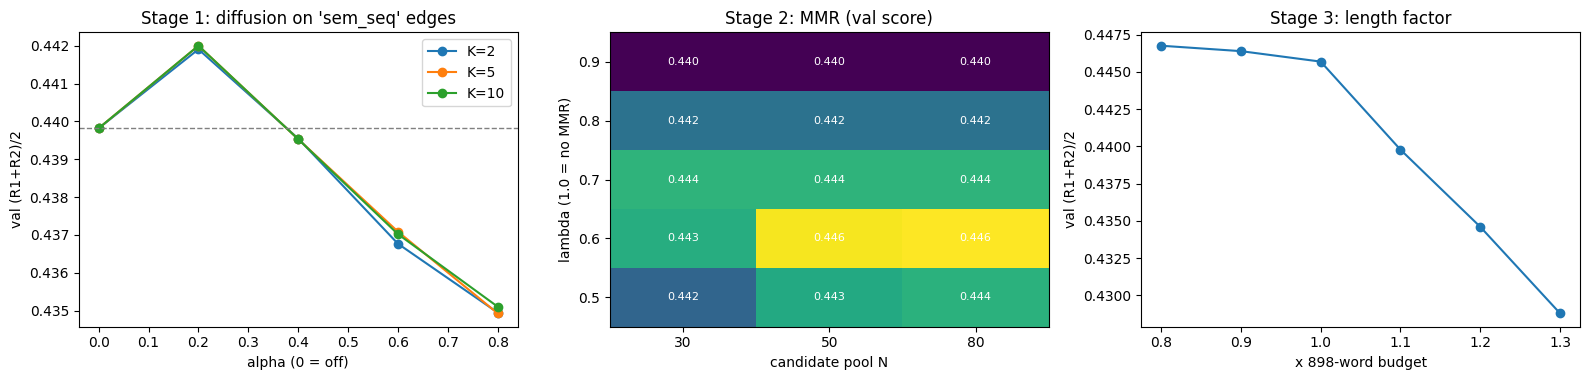

In [9]:
import matplotlib.pyplot as plt
T = TUNING[FINAL_EXP]; base_v = STAGES[FINAL_EXP][0][2]
fig, ax = plt.subplots(1, 3, figsize=(16, 3.9))

s1 = T["s1"]; gsel = (FINAL_CFG["diff"] or {}).get("graph", "all"); nsel = (FINAL_CFG["diff"] or {}).get("norm", NORMS[0])
for K in KS:
    s = s1[(s1.graph == gsel) & (s1.norm == nsel) & (s1.K == K)].sort_values("alpha")
    ax[0].plot([0] + list(s.alpha), [base_v] + list(s.val), marker="o", label=f"K={K}")
ax[0].axhline(base_v, ls="--", c="grey", lw=1); ax[0].set_title(f"Stage 1: diffusion on '{gsel}' edges"); ax[0].set_xlabel("alpha (0 = off)"); ax[0].set_ylabel("val (R1+R2)/2"); ax[0].legend()

s2 = T["s2"][T["s2"].red == RED_SOURCES[0]]; piv = s2.pivot(index="lam", columns="n_cand", values="val").sort_index(ascending=False)
im = ax[1].imshow(piv.values, aspect="auto", cmap="viridis")
ax[1].set_xticks(range(len(piv.columns))); ax[1].set_xticklabels(piv.columns); ax[1].set_yticks(range(len(piv.index))); ax[1].set_yticklabels(piv.index)
for r_ in range(piv.shape[0]):
    for c_ in range(piv.shape[1]): ax[1].text(c_, r_, f"{piv.values[r_, c_]:.3f}", ha="center", va="center", color="w", fontsize=8)
ax[1].set_title("Stage 2: MMR (val score)"); ax[1].set_xlabel("candidate pool N"); ax[1].set_ylabel("lambda (1.0 = no MMR)")

s3 = T["s3"]; ax[2].plot(s3.scale, s3.val, marker="o"); ax[2].set_title("Stage 3: length factor"); ax[2].set_xlabel(f"x {BUDGET}-word budget"); ax[2].set_ylabel("val (R1+R2)/2")
plt.tight_layout(); plt.savefig(Path(OUT_DIR, "figures", "tuning.png"), dpi=130); plt.show()

## 7. What the post-processing changed on one test document

In [10]:
i = test_idx[0]; g = GR[i]; orc = set(g["oracle_idx"])
before = make_selector(FINAL_EXP, FINAL_SEED, dict(diff=None, mmr=None, scale=1.0))(i); after = ext_sel(i)
print(f"{g['doc_id']} | {g['num_nodes']} sentences | top-k picked {len(before)} ({len(orc & set(before))} oracle) | final picked {len(after)} ({len(orc & set(after))} oracle)")
S = get_S(i, "centered")
for tag, ids in (("ADDED by the pipeline", sorted(set(after) - set(before))), ("DROPPED by the pipeline", sorted(set(before) - set(after)))):
    print(f"\n{tag}:")
    for j in ids[:4]:
        nb = max(after, key=lambda k: S[j, k]) if tag.startswith("DROP") else None
        extra = f" (similarity {S[j, nb]:.2f} to selected sentence [{nb}])" if nb is not None and nb != j else ""
        print(f"  [{j}] {'(oracle)' if j in orc else '        '} {g['sentences'][j][:140]}{extra}")

test_1038 | 43 sentences | top-k picked 21 (4 oracle) | final picked 19 (5 oracle)

ADDED by the pipeline:
  [12] (oracle) On September 20, 1944, the Commercial Tax Authorities made a surprise inspection of the premises of the appellants and discovered that they 

DROPPED by the pipeline:
  [18]          On September 2, 1946, a similar suit was brought in regard to the second assessment. (similarity 0.54 to selected sentence [17])
  [28]          (e) shall if he desires to avail himself of the exemption provided in sections 5 and 8 or of the concession of single point taxation provide (similarity 0.44 to selected sentence [34])
  [32]          Section 3 is the charging section and section 5 gives exemption from taxation but that section clearly makes the holding of a licence subjec (similarity 0.45 to selected sentence [38])


## 8. Final checks

In [11]:
sel = json.load(open(Path(OUT_DIR, "selections_final.json")))
n_docs = sum(len(v) for v in sel["docs"].values())
lens = [sum(WORDS[DOC2IDX[(s, d)]][j] for j in v["extractive_idx"]) for s in ("validate", "test") for d, v in sel["docs"][s].items()]
print(f"selections for {n_docs} documents (expected {len(GR)}) | extractive length min/mean/max: {min(lens)}/{np.mean(lens):.0f}/{max(lens)} words (budget {BUDGET} x {FINAL_CFG['scale']})")
assert n_docs == len(GR)
for s_ in SPLIT_NAMES:
    n_files = len(list(Path(OUT_DIR, "summaries/extractive", s_).glob("*.txt")))
    print(f"  {s_}: {n_files} summary files written (expected {len(by_split[s_])})"); assert n_files == len(by_split[s_])
print("Step 5 (LED) reads:  extractive/selections_final.json  -> docs[split][doc_id]['led_input_text']")

selections for 460 documents (expected 460) | extractive length min/mean/max: 439/982/6035 words (budget 898 x 0.8)
  train: 300 summary files written (expected 300)
  validate: 60 summary files written (expected 60)
  test: 100 summary files written (expected 100)
Step 5 (LED) reads:  extractive/selections_final.json  -> docs[split][doc_id]['led_input_text']
